## Comparative Performance of Active Learning Strategies

[Random Sampling] Iteration 1 — Accuracy: 0.9597 | L2 Norm: 20.55
[Random Sampling] Iteration 2 — Accuracy: 0.9573 | L2 Norm: 21.16
[Random Sampling] Iteration 3 — Accuracy: 0.9646 | L2 Norm: 21.57
[Random Sampling] Iteration 4 — Accuracy: 0.9709 | L2 Norm: 21.82
[Random Sampling] Iteration 5 — Accuracy: 0.9710 | L2 Norm: 22.21
[Random Sampling] Iteration 6 — Accuracy: 0.9724 | L2 Norm: 22.39
[Random Sampling] Iteration 7 — Accuracy: 0.9768 | L2 Norm: 22.86
[Random Sampling] Iteration 8 — Accuracy: 0.9752 | L2 Norm: 23.52
[Random Sampling] Iteration 9 — Accuracy: 0.9754 | L2 Norm: 24.14
[Random Sampling] Iteration 10 — Accuracy: 0.9680 | L2 Norm: 24.67
[Random Sampling] Iteration 11 — Accuracy: 0.9784 | L2 Norm: 24.53
[Random Sampling] Iteration 12 — Accuracy: 0.9708 | L2 Norm: 25.09
[Random Sampling] Iteration 13 — Accuracy: 0.9760 | L2 Norm: 26.08
[Random Sampling] Iteration 14 — Accuracy: 0.9781 | L2 Norm: 25.40
[Random Sampling] Iteration 15 — Accuracy: 0.9796 | L2 Norm: 26.90
[Ran

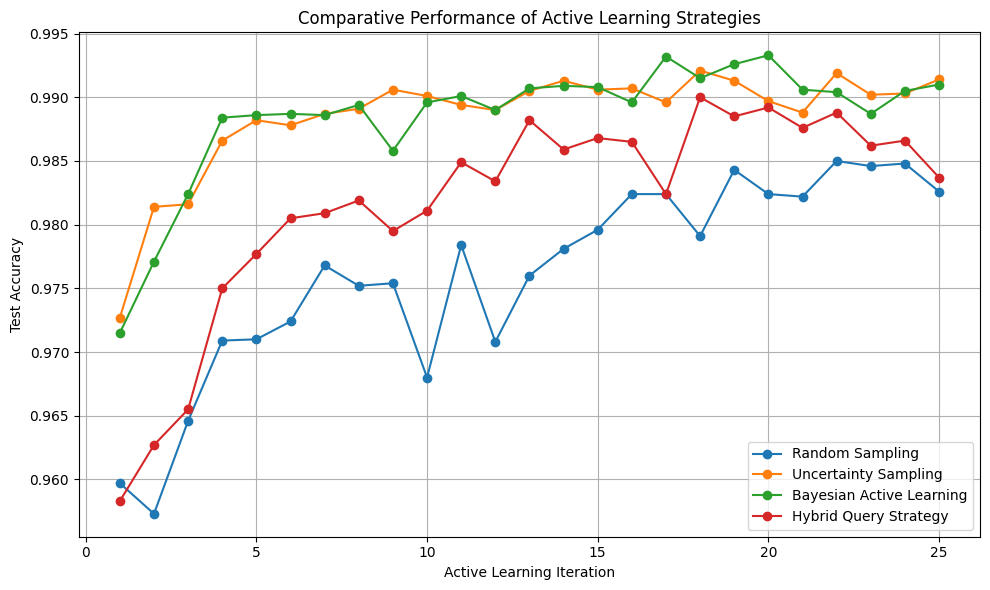

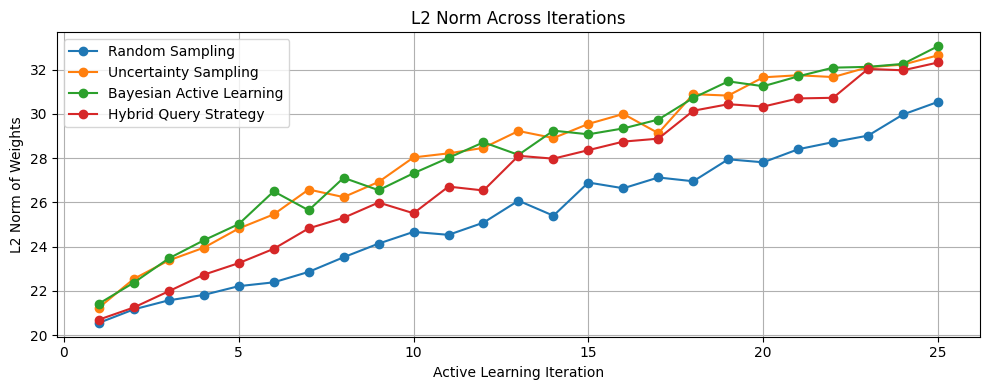

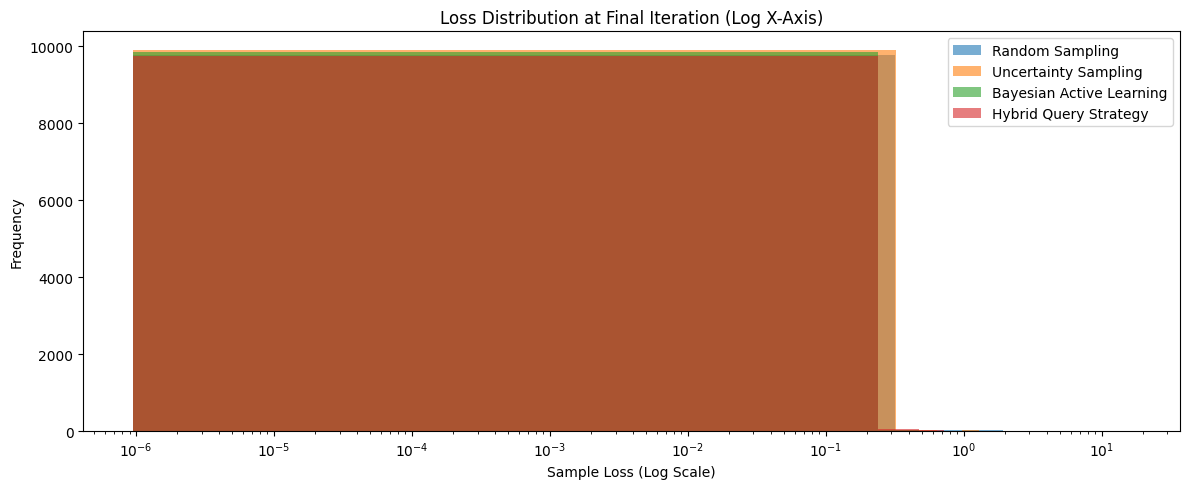

In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

# Define a simple CNN model
def create_cnn_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
        tf.keras.layers.MaxPooling2D(2,2),
        tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
        tf.keras.layers.MaxPooling2D(2,2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')  
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Settings
np.random.seed(42)
initial_labeled_samples = 1000
query_batch_size = 500
num_iterations = 25
epochs_per_round = 10

# Initialize results
approaches = ['Random Sampling', 'Uncertainty Sampling', 'Bayesian Active Learning', 'Hybrid Query Strategy']
accuracies = {approach: [] for approach in approaches}

losses = {approach: [] for approach in approaches}
l2_norms = {approach: [] for approach in approaches}


# Active Learning Strategies
def random_sampling(x_unlabeled, num_samples):
    return np.random.choice(len(x_unlabeled), num_samples, replace=False)

def uncertainty_sampling(model, x_unlabeled, num_samples):
    predictions = model.predict(x_unlabeled)
    uncertainty_scores = -np.sum(predictions * np.log(predictions + 1e-10), axis=1)
    return np.argsort(uncertainty_scores)[-num_samples:]

def bayesian_active_learning(model, x_unlabeled, num_samples, num_mcdropout=10):
    mcd_predictions = np.array([model.predict(x_unlabeled) for _ in range(num_mcdropout)])
    mean_prediction = np.mean(mcd_predictions, axis=0)
    uncertainty_scores = -np.sum(mean_prediction * np.log(mean_prediction + 1e-10), axis=1)
    return np.argsort(uncertainty_scores)[-num_samples:]

def hybrid_query_strategy(model, x_labeled, x_unlabeled, num_samples):
    predictions = model.predict(x_unlabeled)
    uncertainty_scores = -np.sum(predictions * np.log(predictions + 1e-10), axis=1)
    diversity_scores = np.linalg.norm(x_unlabeled.reshape(len(x_unlabeled), -1) - np.mean(x_labeled.reshape(len(x_labeled), -1), axis=0), axis=1)
    hybrid_scores = 0.5 * uncertainty_scores + 0.5 * diversity_scores
    return np.argsort(hybrid_scores)[-num_samples:]

def compute_l2_norm(model):
    l2_total = 0.0
    for layer in model.trainable_weights:
        l2_total += tf.reduce_sum(tf.square(layer)).numpy()
    return np.sqrt(l2_total)


# Run Active Learning
for approach in approaches:
    labeled_indices = np.random.choice(len(x_train), initial_labeled_samples, replace=False)
    unlabeled_indices = np.setdiff1d(np.arange(len(x_train)), labeled_indices)
    x_labeled, y_labeled = x_train[labeled_indices], y_train[labeled_indices]
    x_unlabeled, y_unlabeled = x_train[unlabeled_indices], y_train[unlabeled_indices]
    
    model = create_cnn_model()
    model.fit(x_labeled, y_labeled, epochs=epochs_per_round, verbose=0)
    
    for iteration in range(num_iterations):
        if approach == 'Random Sampling':
            query_indices = random_sampling(x_unlabeled, query_batch_size)
        elif approach == 'Uncertainty Sampling':
            query_indices = uncertainty_sampling(model, x_unlabeled, query_batch_size)
        elif approach == 'Bayesian Active Learning':
            query_indices = bayesian_active_learning(model, x_unlabeled, query_batch_size)
        elif approach == 'Hybrid Query Strategy':
            query_indices = hybrid_query_strategy(model, x_labeled, x_unlabeled, query_batch_size)
        
        # Add queried samples to labeled dataset
        new_labeled_indices = unlabeled_indices[query_indices]
        x_labeled = np.concatenate((x_labeled, x_unlabeled[query_indices]), axis=0)
        y_labeled = np.concatenate((y_labeled, y_unlabeled[query_indices]), axis=0)
        unlabeled_indices = np.setdiff1d(unlabeled_indices, new_labeled_indices)
        x_unlabeled, y_unlabeled = x_train[unlabeled_indices], y_train[unlabeled_indices]
        
        # Retrain model
        model = create_cnn_model()
        model.fit(x_labeled, y_labeled, epochs=epochs_per_round, verbose=0)
        test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
        y_pred_probs = model.predict(x_test, verbose=0)
        y_pred_loss = tf.keras.losses.sparse_categorical_crossentropy(y_test, y_pred_probs).numpy()
        l2 = compute_l2_norm(model)

        accuracies[approach].append(test_acc)
        losses[approach].append(y_pred_loss)
        l2_norms[approach].append(l2)
        
        print(f"[{approach}] Iteration {iteration+1} — Accuracy: {test_acc:.4f} | L2 Norm: {l2:.2f}")

# Plot
plt.figure(figsize=(10, 6))
for approach in approaches:
    iterations = len(accuracies[approach])
    plt.plot(range(1, iterations + 1), accuracies[approach], marker='o', label=approach)
plt.xlabel('Active Learning Iteration')
plt.ylabel('Test Accuracy')
plt.title('Comparative Performance of Active Learning Strategies')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# Plot L2 norm progression
plt.figure(figsize=(10, 4))
for approach in approaches:
    iterations = len(l2_norms[approach])
    plt.plot(range(1, iterations + 1), l2_norms[approach], marker='o', label=approach)
plt.xlabel('Active Learning Iteration')
plt.ylabel('L2 Norm of Weights')
plt.title('L2 Norm Across Iterations')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# Plot loss distribution at final iteration
plt.figure(figsize=(12, 5))
for approach in approaches:
    final_losses = losses[approach][-1]
    plt.hist(final_losses, bins=50, alpha=0.6, label=approach)
plt.xlabel('Sample Loss (Log Scale)')
plt.ylabel('Frequency')
plt.title('Loss Distribution at Final Iteration (Log X-Axis)')
plt.xscale('log')
plt.legend()
plt.tight_layout()
plt.show()

